# Project 2: Diabetes Classification

This notebook builds an end-to-end binary classification workflow that predicts whether a patient has diabetes from diagnostic measurements.

**Workflow:** data loading, cleaning, exploratory analysis, preprocessing, feature engineering, comparison of six classifiers, evaluation, model saving and prediction on new data.

## 1. Project Introduction

Early screening for diabetes allows earlier treatment and lifestyle change. The Pima Indians Diabetes dataset (National Institute of Diabetes and Digestive and Kidney Diseases) contains medical measurements of women of Pima Indian heritage who are at least 21 years old, together with a flag that shows whether the patient developed diabetes within five years.

## 2. Problem Statement

Given eight diagnostic measurements, predict `Outcome` (1 = diabetes, 0 = no diabetes).

- **Type:** supervised learning, binary classification
- **Models compared:** Logistic Regression, K-Nearest Neighbors, Support Vector Machine, Decision Tree, Random Forest, Gradient Boosting
- **Metrics:** accuracy, precision, recall, F1 and ROC AUC. Recall matters because a missed diabetic patient is more costly than a false alarm. Model selection uses stratified 5-fold cross-validation ROC AUC on the training set.

In [1]:
import json
import warnings

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, RobustScaler
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

from features import (
    ENGINEERED_COLUMNS,
    RAW_FEATURE_COLUMNS,
    TARGET_COLUMN,
    ZERO_AS_MISSING_COLUMNS,
    add_features,
    replace_zeros_with_missing,
)

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
pd.set_option("display.max_columns", 50)
plt.rcParams["figure.figsize"] = (9, 5)
plt.rcParams["axes.grid"] = True

## 3. Dataset Loading

The file has no header row, so the column names are supplied while reading. It is loaded directly from a public GitHub raw URL.

In [2]:
DATA_URLS = [
    "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv",
]
COLUMN_NAMES = RAW_FEATURE_COLUMNS + [TARGET_COLUMN]


def load_dataset(urls, **read_options):
    last_error = None
    for url in urls:
        try:
            return pd.read_csv(url, **read_options)
        except Exception as error:
            last_error = error
    raise RuntimeError(f"None of the dataset URLs could be loaded: {urls}") from last_error


diabetes = load_dataset(DATA_URLS, header=None, names=COLUMN_NAMES)
print(f"Rows: {diabetes.shape[0]:,}  Columns: {diabetes.shape[1]}")
diabetes.head()

Rows: 768  Columns: 9


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## 4. Data Overview

In [3]:
diabetes.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [4]:
diabetes.describe().T

,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
DiabetesPedigreeFunction,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [5]:
zero_counts = (diabetes[RAW_FEATURE_COLUMNS] == 0).sum().rename("zero_values")
print(f"Duplicate rows: {diabetes.duplicated().sum()}")
print(f"Missing values (NaN): {int(diabetes.isna().sum().sum())}")
zero_counts.to_frame().assign(zero_percent=(zero_counts / len(diabetes) * 100).round(1))

Duplicate rows: 0
Missing values (NaN): 0


,zero_values,zero_percent
Pregnancies,111,14.5
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4
DiabetesPedigreeFunction,0,0.0
Age,0,0.0


## 5. Data Cleaning

The dataset has no `NaN` values, but several columns contain zeros that are physiologically impossible (a glucose, blood pressure, skin thickness, insulin or BMI of zero). These zeros are placeholders for missing measurements. `Pregnancies` can legitimately be zero, so it is left untouched.

For analysis the zeros are converted to `NaN` on a copy of the data. In the modelling pipeline the same conversion is part of `add_features`, and the imputation values are learned from the training data only.

In [6]:
diabetes_clean = diabetes.drop_duplicates().reset_index(drop=True)
diabetes_analysis = replace_zeros_with_missing(diabetes_clean)
missing_after_conversion = pd.DataFrame(
    {
        "missing_values": diabetes_analysis[ZERO_AS_MISSING_COLUMNS].isna().sum(),
        "missing_percent": (diabetes_analysis[ZERO_AS_MISSING_COLUMNS].isna().mean() * 100).round(1),
    }
)
print(f"Rows after removing duplicates: {len(diabetes_clean):,}")
missing_after_conversion

Rows after removing duplicates: 768


,missing_values,missing_percent
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


## 6. Exploratory Data Analysis

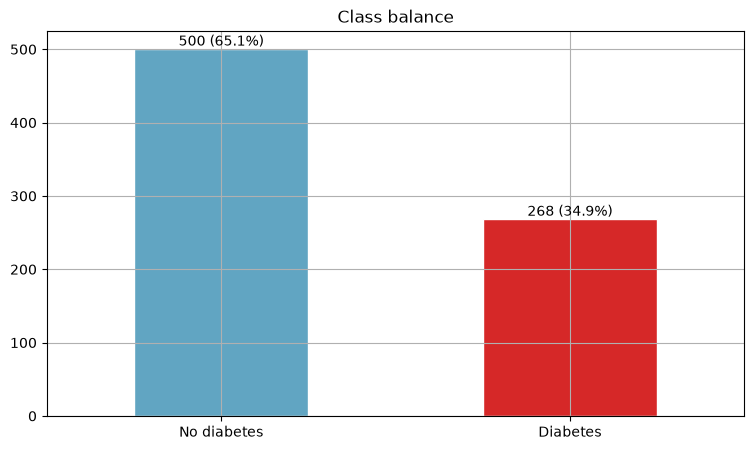

In [7]:
class_counts = diabetes_clean[TARGET_COLUMN].value_counts().sort_index()
class_counts.index = ["No diabetes", "Diabetes"]
ax = class_counts.plot(kind="bar", color=["#61a5c2", "#d62828"], edgecolor="white")
for position, value in enumerate(class_counts):
    ax.text(position, value + 5, f"{value} ({value / class_counts.sum():.1%})", ha="center")
ax.set_title("Class balance")
ax.tick_params(axis="x", rotation=0)
plt.show()

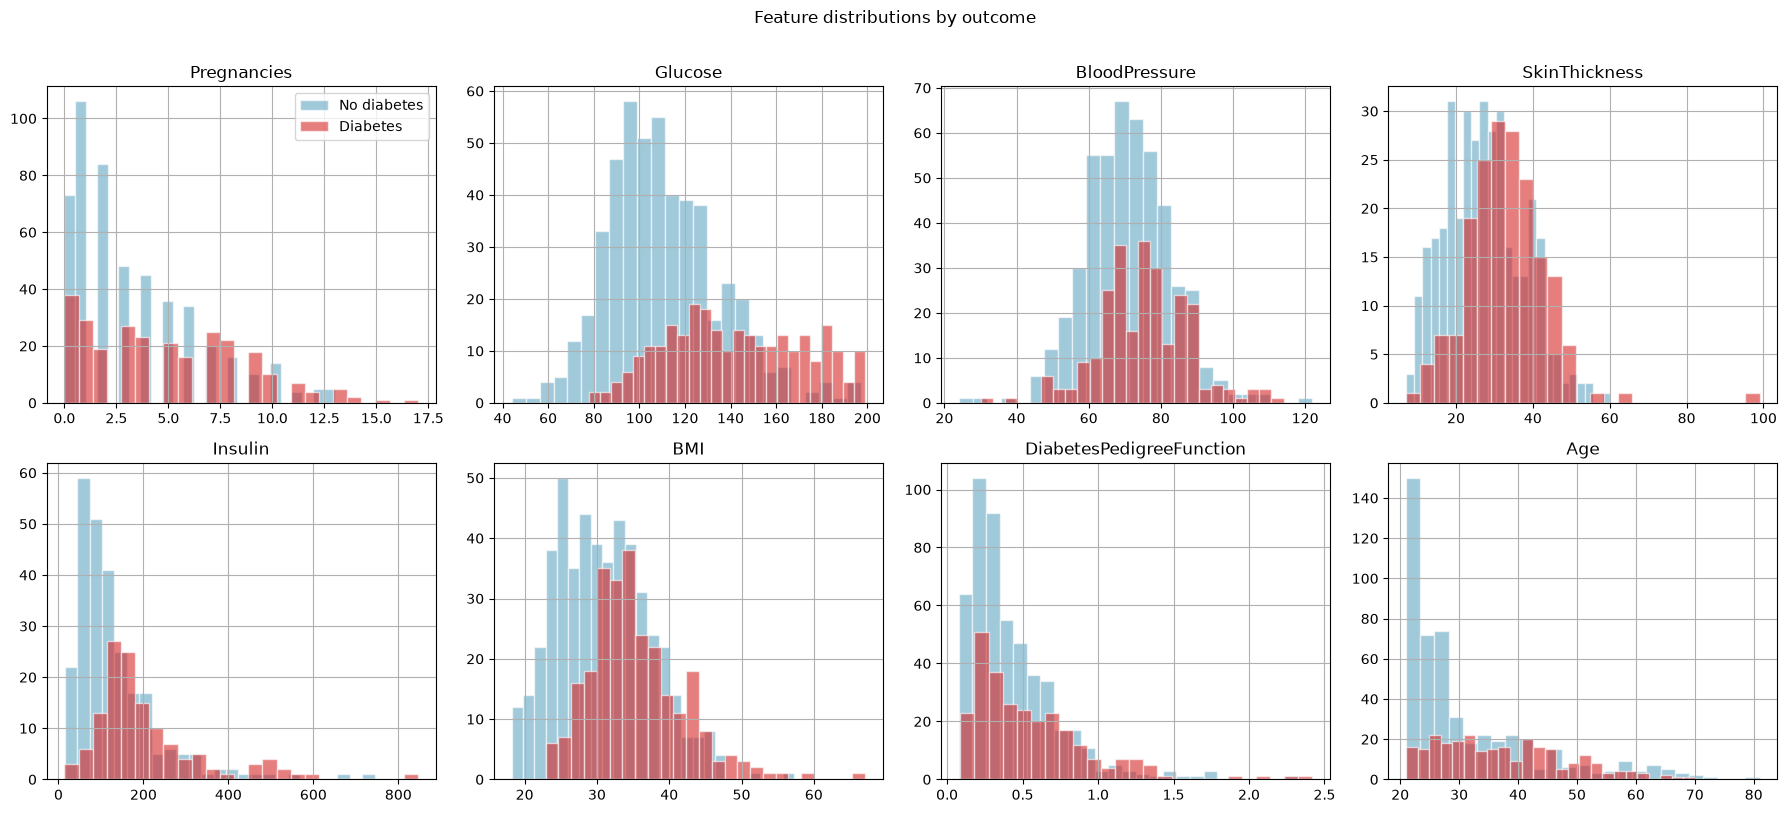

In [8]:
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for axis, column in zip(axes.ravel(), RAW_FEATURE_COLUMNS):
    for outcome, color, label in [(0, "#61a5c2", "No diabetes"), (1, "#d62828", "Diabetes")]:
        values = diabetes_analysis.loc[diabetes_analysis[TARGET_COLUMN] == outcome, column].dropna()
        axis.hist(values, bins=25, alpha=0.6, color=color, label=label, edgecolor="white")
    axis.set_title(column)
axes[0, 0].legend()
plt.suptitle("Feature distributions by outcome", y=1.01)
plt.tight_layout()
plt.show()

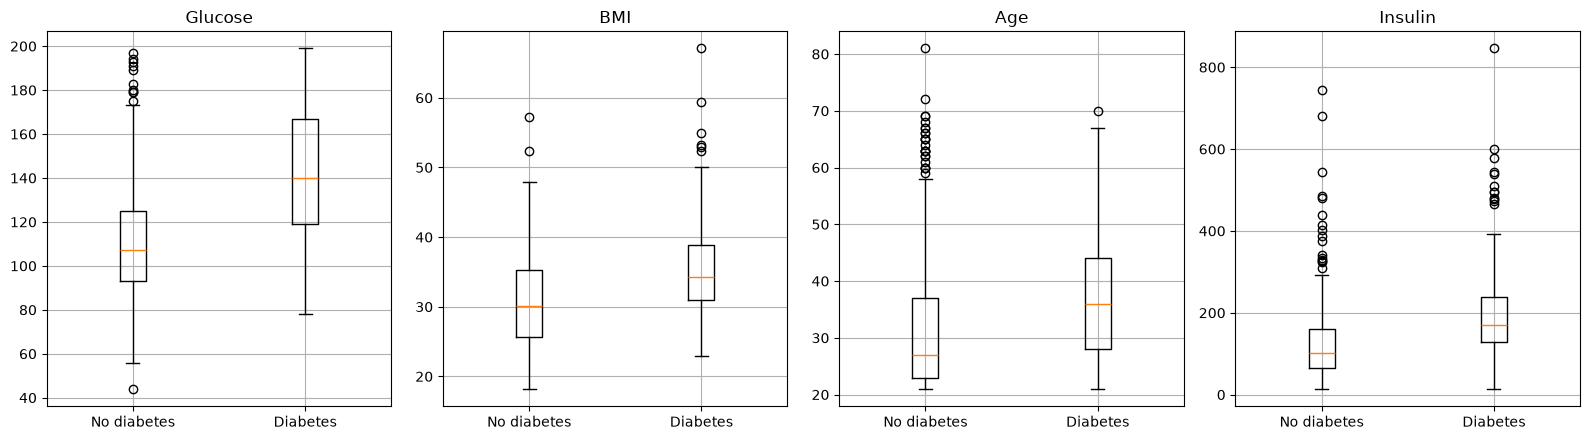

In [9]:
boxplot_columns = ["Glucose", "BMI", "Age", "Insulin"]
fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
for axis, column in zip(axes, boxplot_columns):
    groups = [
        diabetes_analysis.loc[diabetes_analysis[TARGET_COLUMN] == outcome, column].dropna().values
        for outcome in (0, 1)
    ]
    axis.boxplot(groups)
    axis.set_xticks([1, 2])
    axis.set_xticklabels(["No diabetes", "Diabetes"])
    axis.set_title(column)
plt.tight_layout()
plt.show()

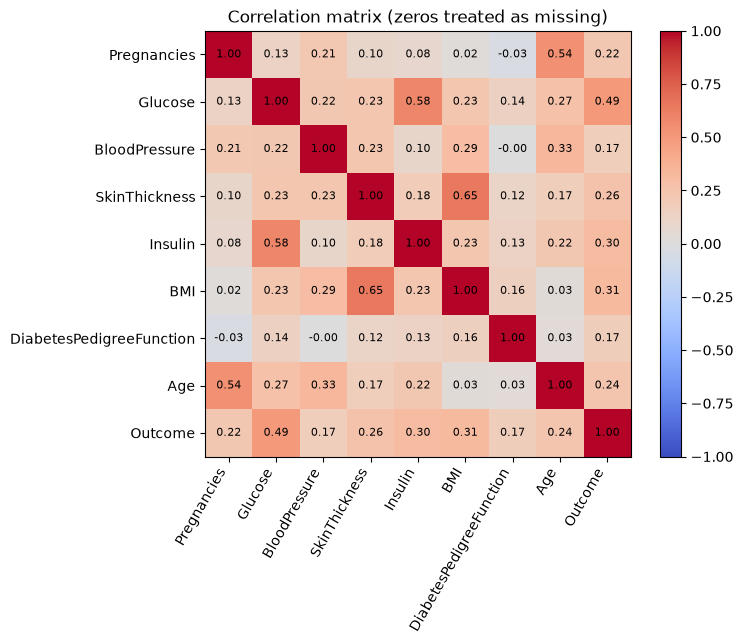

Glucose                     0.495
BMI                         0.314
Insulin                     0.303
SkinThickness               0.259
Age                         0.238
Pregnancies                 0.222
DiabetesPedigreeFunction    0.174
BloodPressure               0.171
Name: Outcome, dtype: float64

In [10]:
correlations = diabetes_analysis.corr()
fig, ax = plt.subplots(figsize=(8, 6.5))
image = ax.imshow(correlations, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(correlations.columns)))
ax.set_yticks(range(len(correlations.columns)))
ax.set_xticklabels(correlations.columns, rotation=60, ha="right")
ax.set_yticklabels(correlations.columns)
for row_index in range(len(correlations)):
    for column_index in range(len(correlations)):
        ax.text(column_index, row_index, f"{correlations.iloc[row_index, column_index]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False)
fig.colorbar(image)
ax.set_title("Correlation matrix (zeros treated as missing)")
plt.tight_layout()
plt.show()
correlations[TARGET_COLUMN].drop(TARGET_COLUMN).sort_values(ascending=False).round(3)

## 7. Data Preprocessing

The data is split into training and test sets **before** anything is learned from it. The split is stratified so both sets keep the same share of positive cases. Median imputation and robust scaling are placed inside the pipeline so that they are fitted on training folds only. `RobustScaler` uses the median and the interquartile range, so extreme values such as very high insulin readings do not dominate the scaling.

In [11]:
feature_frame = diabetes_clean[RAW_FEATURE_COLUMNS]
target_series = diabetes_clean[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    feature_frame, target_series, test_size=0.2, stratify=target_series, random_state=RANDOM_STATE
)
print(f"Training rows: {len(X_train):,}  Test rows: {len(X_test):,}")
print(f"Positive rate  train: {y_train.mean():.3f}  test: {y_test.mean():.3f}")


def build_pipeline(estimator):
    preprocessing = Pipeline(
        [("imputer", SimpleImputer(strategy="median")), ("scaler", RobustScaler())]
    )
    return Pipeline(
        [
            ("features", FunctionTransformer(add_features)),
            ("preprocess", preprocessing),
            ("model", estimator),
        ]
    )

Training rows: 614  Test rows: 154
Positive rate  train: 0.349  test: 0.351


## 8. Feature Engineering

Three features are added by `add_features` in `features.py`:

- `insulin_missing`: flags that no insulin measurement was taken. Missingness itself can carry information.
- `glucose_bmi_index`: the product of glucose and BMI, which captures the combined metabolic risk.
- `pregnancies_per_decade`: the number of pregnancies relative to age.

In [12]:
engineered_preview = add_features(X_train)
engineered_correlation = (
    engineered_preview[ENGINEERED_COLUMNS]
    .assign(**{TARGET_COLUMN: y_train.values})
    .corr()[TARGET_COLUMN]
    .drop(TARGET_COLUMN)
)
print("Correlation of engineered features with the target (training data):")
print(engineered_correlation.round(3))
engineered_preview[ENGINEERED_COLUMNS].head()

Correlation of engineered features with the target (training data):
insulin_missing           0.027
glucose_bmi_index         0.546
pregnancies_per_decade    0.140
Name: Outcome, dtype: float64


,insulin_missing,glucose_bmi_index,pregnancies_per_decade
353,0,24.480,0.416667
711,0,37.296,1.250000
373,0,36.645,0.800000
46,1,43.362,0.344828
682,0,42.370,0.000000


## 9. Model Training

Six different algorithm families are trained with the same pipeline. Class weights are balanced where the algorithm supports them because only about a third of the patients are positive.

In [13]:
candidate_models = {
    "Logistic Regression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=15),
    "Support Vector Machine": SVC(kernel="rbf", C=1.0, class_weight="balanced", probability=True, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=4, min_samples_leaf=10, class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, max_depth=6, min_samples_leaf=3, class_weight="balanced", n_jobs=-1, random_state=RANDOM_STATE
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=150, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=RANDOM_STATE
    ),
}

cross_validation = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"roc_auc": "roc_auc", "f1": "f1", "recall": "recall", "precision": "precision", "accuracy": "accuracy"}
cross_validation_rows = []
fitted_pipelines = {}

for model_name, estimator in candidate_models.items():
    pipeline = build_pipeline(estimator)
    scores = cross_validate(pipeline, X_train, y_train, cv=cross_validation, scoring=scoring)
    cross_validation_rows.append(
        {"model": model_name, **{f"cv_{metric}": scores[f"test_{metric}"].mean() for metric in scoring}, "cv_roc_auc_std": scores["test_roc_auc"].std()}
    )
    fitted_pipelines[model_name] = pipeline.fit(X_train, y_train)
    print(f"Trained {model_name}")

cross_validation_table = pd.DataFrame(cross_validation_rows).set_index("model")
cross_validation_table.round(4)

Trained Logistic Regression
Trained K-Nearest Neighbors
Trained Support Vector Machine
Trained Decision Tree
Trained Random Forest
Trained Gradient Boosting


,cv_roc_auc,cv_f1,cv_recall,cv_precision,cv_accuracy,cv_roc_auc_std
model,,,,,,
Logistic Regression,0.8446,0.6793,0.7243,0.6441,0.7622,0.0151
K-Nearest Neighbors,0.7789,0.5798,0.5234,0.6544,0.7328,0.0399
Support Vector Machine,0.8185,0.6761,0.7853,0.5983,0.7362,0.0348
Decision Tree,0.7696,0.6089,0.7203,0.5374,0.6791,0.0146
Random Forest,0.8365,0.6845,0.7334,0.6434,0.7638,0.0230
Gradient Boosting,0.8195,0.6116,0.5841,0.6475,0.7410,0.0241


## 10. Model Comparison

All models are scored on the untouched test set.

In [14]:
def classification_scores(model_name, fitted_pipeline, features_frame, target_values):
    predicted_labels = fitted_pipeline.predict(features_frame)
    predicted_probabilities = fitted_pipeline.predict_proba(features_frame)[:, 1]
    return {
        "model": model_name,
        "accuracy": accuracy_score(target_values, predicted_labels),
        "precision": precision_score(target_values, predicted_labels),
        "recall": recall_score(target_values, predicted_labels),
        "f1": f1_score(target_values, predicted_labels),
        "roc_auc": roc_auc_score(target_values, predicted_probabilities),
    }


test_table = pd.DataFrame(
    [classification_scores(name, pipeline, X_test, y_test) for name, pipeline in fitted_pipelines.items()]
).set_index("model")
test_table.round(4)

,accuracy,precision,recall,f1,roc_auc
model,,,,,
Logistic Regression,0.7403,0.6061,0.7407,0.6667,0.8207
K-Nearest Neighbors,0.7143,0.6000,0.5556,0.5769,0.7616
Support Vector Machine,0.6948,0.5493,0.7222,0.6240,0.7865
Decision Tree,0.6948,0.5402,0.8704,0.6667,0.7817
Random Forest,0.7338,0.5970,0.7407,0.6612,0.8148
Gradient Boosting,0.7468,0.6596,0.5741,0.6139,0.8128


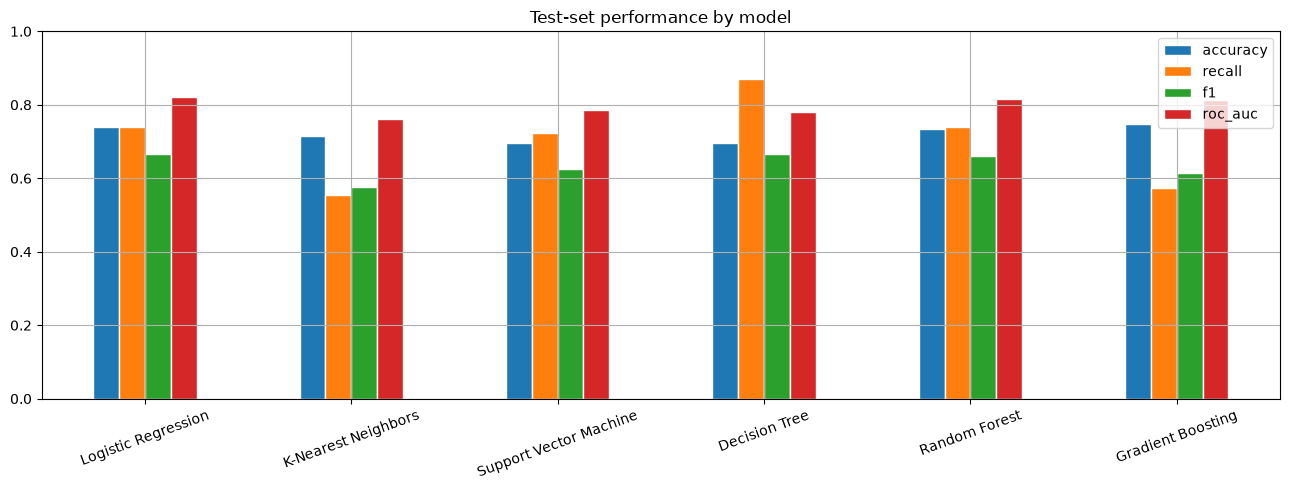

In [15]:
ax = test_table[["accuracy", "recall", "f1", "roc_auc"]].plot(kind="bar", figsize=(13, 5), edgecolor="white")
ax.set_title("Test-set performance by model")
ax.set_xlabel("")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

## 11. Model Evaluation

The best model is selected by cross-validated ROC AUC and then examined in detail.

In [16]:
best_model_name = cross_validation_table["cv_roc_auc"].idxmax()
best_pipeline = fitted_pipelines[best_model_name]
best_predictions = best_pipeline.predict(X_test)
print(f"Selected model: {best_model_name}\n")
print(classification_report(y_test, best_predictions, target_names=["No diabetes", "Diabetes"]))

Selected model: Logistic Regression

              precision    recall  f1-score   support

 No diabetes       0.84      0.74      0.79       100
    Diabetes       0.61      0.74      0.67        54

    accuracy                           0.74       154
   macro avg       0.72      0.74      0.73       154
weighted avg       0.76      0.74      0.74       154



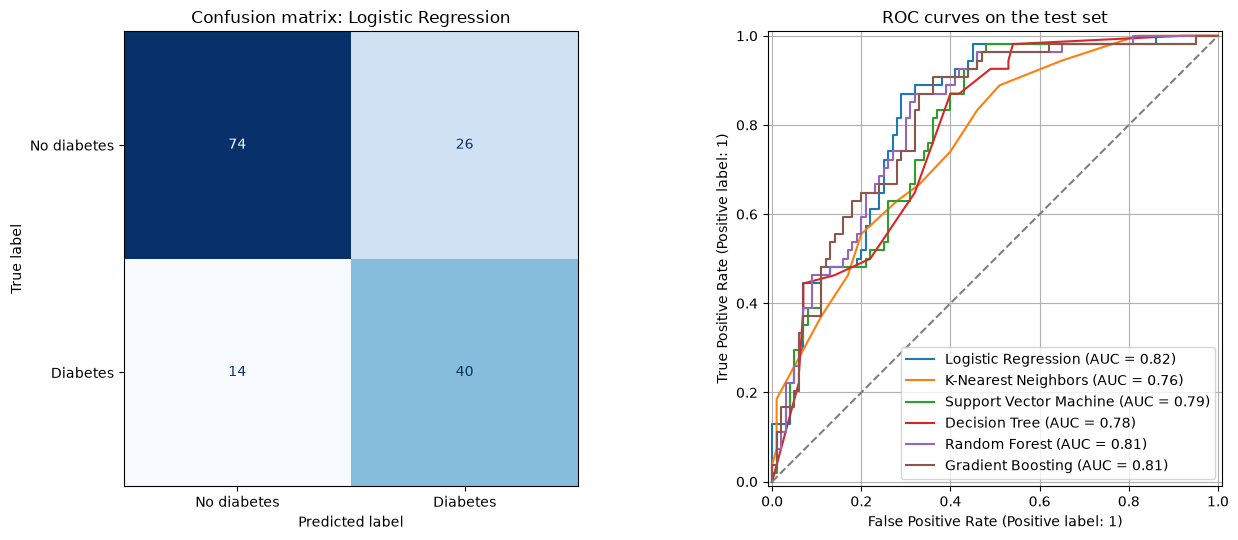

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ConfusionMatrixDisplay.from_predictions(
    y_test, best_predictions, display_labels=["No diabetes", "Diabetes"], cmap="Blues", ax=axes[0], colorbar=False
)
axes[0].set_title(f"Confusion matrix: {best_model_name}")
axes[0].grid(False)
for model_name, pipeline in fitted_pipelines.items():
    RocCurveDisplay.from_estimator(pipeline, X_test, y_test, ax=axes[1], name=model_name)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="grey")
axes[1].set_title("ROC curves on the test set")
plt.tight_layout()
plt.show()

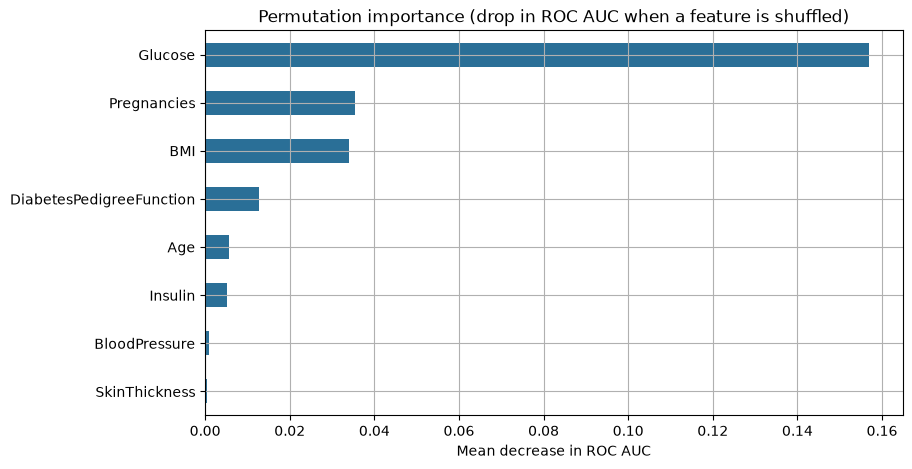

Glucose                     0.1570
Pregnancies                 0.0354
BMI                         0.0340
DiabetesPedigreeFunction    0.0126
Age                         0.0057
Insulin                     0.0052
BloodPressure               0.0010
SkinThickness               0.0004
dtype: float64

In [18]:
importance_result = permutation_importance(
    best_pipeline, X_test, y_test, n_repeats=20, random_state=RANDOM_STATE, scoring="roc_auc", n_jobs=-1
)
feature_importance = pd.Series(importance_result.importances_mean, index=X_test.columns).sort_values(ascending=False)
feature_importance.sort_values().plot(kind="barh", color="#2a6f97", figsize=(9, 5))
plt.title("Permutation importance (drop in ROC AUC when a feature is shuffled)")
plt.xlabel("Mean decrease in ROC AUC")
plt.show()
feature_importance.round(4)

## 12. Best Model Selection

The model with the highest mean cross-validated ROC AUC on the training data is selected. Using cross-validation for the choice keeps the test set as an unbiased final check.

In [19]:
best_test_metrics = classification_scores(best_model_name, best_pipeline, X_test, y_test)
for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(f"Test {metric:<9}: {best_test_metrics[metric]:.4f}")

Test accuracy : 0.7403
Test precision: 0.6061
Test recall   : 0.7407
Test f1       : 0.6667
Test roc_auc  : 0.8207


## 13. Model Saving

The complete pipeline is saved as `model.pkl`. The file `metadata.json` stores the input ranges, the comparison table, the feature importances and the ROC curve for the Streamlit app.

In [20]:
def json_default(value):
    return value.item() if hasattr(value, "item") else str(value)


cleaned_features = replace_zeros_with_missing(feature_frame)
numeric_ranges = {
    column: {
        "min": float(cleaned_features[column].min()),
        "max": float(cleaned_features[column].max()),
        "median": float(cleaned_features[column].median()),
    }
    for column in RAW_FEATURE_COLUMNS
}
false_positive_rate, true_positive_rate, _ = roc_curve(y_test, best_pipeline.predict_proba(X_test)[:, 1])
curve_step = max(len(false_positive_rate) // 100, 1)

metadata = {
    "project": "Diabetes Classification",
    "target": TARGET_COLUMN,
    "best_model": best_model_name,
    "decision_threshold": 0.5,
    "numeric_ranges": numeric_ranges,
    "zero_as_missing_columns": ZERO_AS_MISSING_COLUMNS,
    "test_metrics": best_test_metrics,
    "model_comparison": cross_validation_table.join(test_table).reset_index().to_dict(orient="records"),
    "feature_importance": feature_importance.to_dict(),
    "roc_curve": {
        "false_positive_rate": false_positive_rate[::curve_step].tolist(),
        "true_positive_rate": true_positive_rate[::curve_step].tolist(),
    },
    "training_rows": int(len(X_train)),
    "test_rows": int(len(X_test)),
}

joblib.dump(best_pipeline, "model.pkl")
with open("metadata.json", "w", encoding="utf-8") as metadata_file:
    json.dump(metadata, metadata_file, indent=2, default=json_default)
print("Saved model.pkl and metadata.json")

Saved model.pkl and metadata.json


## 14. Prediction on New Data

The saved model is loaded from disk and applied to new patients. A value of `0` or `NaN` in a measurement column means the value is unknown and is handled by the pipeline.

In [21]:
loaded_model = joblib.load("model.pkl")

new_patients = pd.DataFrame(
    [
        {"Pregnancies": 2, "Glucose": 95, "BloodPressure": 70, "SkinThickness": 25, "Insulin": 90, "BMI": 24.5, "DiabetesPedigreeFunction": 0.25, "Age": 28},
        {"Pregnancies": 6, "Glucose": 168, "BloodPressure": 82, "SkinThickness": 35, "Insulin": 0, "BMI": 38.2, "DiabetesPedigreeFunction": 0.85, "Age": 51},
        {"Pregnancies": 1, "Glucose": 118, "BloodPressure": np.nan, "SkinThickness": 30, "Insulin": 130, "BMI": 31.0, "DiabetesPedigreeFunction": 0.45, "Age": 37},
    ]
)[RAW_FEATURE_COLUMNS]

probabilities = loaded_model.predict_proba(new_patients)[:, 1]
decision_threshold = metadata["decision_threshold"]
new_patients["diabetes_probability"] = probabilities.round(3)
new_patients["prediction"] = np.where(probabilities >= decision_threshold, "Diabetes", "No diabetes")
consistency_check = np.allclose(loaded_model.predict_proba(X_test.head(50)), best_pipeline.predict_proba(X_test.head(50)))
print(f"Loaded model matches the in-memory model: {consistency_check}")
new_patients

Loaded model matches the in-memory model: True


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,diabetes_probability,prediction
0,2,95,70.0,25,90,24.5,0.25,28,0.060,No diabetes
1,6,168,82.0,35,0,38.2,0.85,51,0.960,Diabetes
2,1,118,NaN,30,130,31.0,0.45,37,0.274,No diabetes


## 15. Final Conclusion

In [22]:
top_features = ", ".join(feature_importance.head(3).index)
print(f"Best model by cross-validated ROC AUC: {best_model_name}")
print(
    f"Test accuracy {best_test_metrics['accuracy']:.3f} | recall {best_test_metrics['recall']:.3f} | "
    f"precision {best_test_metrics['precision']:.3f} | F1 {best_test_metrics['f1']:.3f} | ROC AUC {best_test_metrics['roc_auc']:.3f}"
)
print(f"Most influential features: {top_features}")
print()
print("Model ranking on the test set (ROC AUC):")
print(test_table["roc_auc"].sort_values(ascending=False).round(4).to_string())

Best model by cross-validated ROC AUC: Logistic Regression
Test accuracy 0.740 | recall 0.741 | precision 0.606 | F1 0.667 | ROC AUC 0.821
Most influential features: Glucose, Pregnancies, BMI

Model ranking on the test set (ROC AUC):
model
Logistic Regression       0.8207
Random Forest             0.8148
Gradient Boosting         0.8128
Support Vector Machine    0.7865
Decision Tree             0.7817
K-Nearest Neighbors       0.7616


**Summary of the approach**

- Physiologically impossible zeros were treated as missing values and imputed with training medians, and robust scaling reduced the influence of outliers.
- Models from six families were compared with stratified cross-validation, and the final choice never used the test set.
- Class weighting and recall-aware evaluation reflect that missing a positive case is costly.

**Limitations and next steps**

- The dataset is small (a few hundred patients from one population), so scores have noticeable variance and may not transfer to other groups.
- The model is an educational screening aid and not a medical diagnosis.
- Possible improvements: hyperparameter search, probability calibration, a decision threshold tuned for a target recall, and external validation data.